# Notebook 10 — Exploratory Data Analysis (EDA)

**Project:** Dengue Disease Prediction — Sri Lanka  
**Input:** Integrated monthly data produced by **Notebook 09**  
**Unit of observation:** One administrative district in one calendar month

### Research questions for this notebook
1. How did reported dengue cases vary across years and months?
2. Which administrative districts recorded the largest totals?
3. What seasonal patterns appear in dengue and environmental observations?
4. What *descriptive associations* appear between dengue and weather variables?
5. How does dengue incidence per 100,000 residents differ across districts (where population is available)?

### Strict methodological rules
- **2024 is the untouched forecasting test year.** This notebook uses **2010–2023** for exploratory relationships and plots. It checks 2024 only for input coverage, not for feature selection or tuning.
- Monthly dengue values may be **fractional** because Notebook 04 distributed weekly case counts proportionally across calendar days. Do not round them.
- Population is available **only from 2014**; population-adjusted analysis uses **2014–2023**.
- Correlation is **not causation**, and same-month associations are not forecasts.
- This notebook does **not** train models, fit imputers, or create LSTM features. Those steps belong to later notebooks.
- Figures and summary tables are saved without modifying the integrated source CSVs.

## 1 — Imports and locate project root
Run this notebook from `D:\Dengue_Project\notebooks` or from the project root in VS Code. Select the project's `.venv` kernel.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

candidates = [Path.cwd(), *Path.cwd().parents]
PROJECT_ROOT = next((p for p in candidates if (p / "data" / "processed").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot locate project/data/processed. Open D:\\Dengue_Project in VS Code.")

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
TABLES_DIR.mkdir(parents=True, exist_ok=True)

WEATHER_COLUMNS = ["temperature_mean_c", "humidity_mean_percent", "rainfall_total_mm", "wind_speed_mean_kmh"]
KEYS = ["administrative_district", "date"]
MONTH_NAMES = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.rcParams.update({"figure.figsize": (10, 5), "axes.grid": True, "grid.alpha": 0.2})

def save_figure(filename):
    path = FIGURES_DIR / filename
    plt.tight_layout()
    plt.savefig(path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close()
    print("Saved figure:", path.relative_to(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: d:\Dengue_Project


## 2 — Load Notebook 09 outputs
These are the **actual filenames written by Notebook 09**. Run Notebook 09 first if they are absent.

In [2]:
paths = {
    "dengue_weather": PROCESSED_DIR / "dengue_weather_monthly_2010_2024.csv",
    "population_inclusive": PROCESSED_DIR / "dengue_weather_population_monthly_2014_2024.csv",
    "population_strict": PROCESSED_DIR / "dengue_weather_population_complete_months_2014_2024.csv",
}
for name, path in paths.items():
    print(f"{name:23s} | exists={path.is_file()} | {path.name}")
    if not path.is_file():
        raise FileNotFoundError(f"Missing Notebook 09 output: {path}")

full = pd.read_csv(paths["dengue_weather"], parse_dates=["date"])
with_population = pd.read_csv(paths["population_inclusive"], parse_dates=["date"])
strict = pd.read_csv(paths["population_strict"], parse_dates=["date"])
for label, frame in [("Full dengue-weather", full), ("Population-inclusive", with_population), ("Complete-month population", strict)]:
    print(f"{label:28s} | rows={len(frame):,} | districts={frame['administrative_district'].nunique()} | months={frame['date'].nunique()}")
display(full.head(3))

dengue_weather          | exists=True | dengue_weather_monthly_2010_2024.csv
population_inclusive    | exists=True | dengue_weather_population_monthly_2014_2024.csv
population_strict       | exists=True | dengue_weather_population_complete_months_2014_2024.csv
Full dengue-weather          | rows=4,500 | districts=25 | months=180
Population-inclusive         | rows=3,300 | districts=25 | months=132
Complete-month population    | rows=3,275 | districts=25 | months=131


,date,administrative_district,dengue_cases,temperature_mean_c,temperature_min_c,temperature_max_c,humidity_mean_percent,humidity_min_percent,humidity_max_percent,rainfall_total_mm,rainfall_max_hourly_mm,rainy_days,wind_speed_mean_kmh,wind_speed_max_kmh,complete_weather_month
0,2010-01-01,Ampara,116.428571,25.599833,22.20,28.95,80.270667,59.5,96.5,88.371429,4.35,21.714286,12.701000,24.15,False
1,2010-02-01,Ampara,124.428571,26.125893,22.20,31.40,78.548750,56.0,94.0,72.071429,4.35,12.571429,11.530714,24.15,True
2,2010-03-01,Ampara,72.857143,27.752097,22.55,32.55,75.846774,51.0,94.0,25.885714,2.45,14.500000,9.655000,21.65,True


## 3 — Validate integrated data before plotting
The notebook should stop if the integration keys or required measurements are invalid. Unexpected sizes are flagged rather than silently repaired.

In [3]:
required_full = set(KEYS + ["dengue_cases", "complete_weather_month"] + WEATHER_COLUMNS)
required_population = set(KEYS + ["dengue_cases", "population"] + WEATHER_COLUMNS)
for label, frame, required in [
    ("full", full, required_full),
    ("population", with_population, required_population),
    ("strict", strict, required_population),
]:
    absent = required.difference(frame.columns)
    if absent:
        raise ValueError(f"{label}: missing columns {sorted(absent)}")
    if frame[KEYS].isna().any().any() or frame.duplicated(KEYS).any():
        raise ValueError(f"{label}: null or duplicate district-month keys")
    if not frame["date"].dt.is_month_start.all():
        raise ValueError(f"{label}: date must be the first day of a month")
    if frame["dengue_cases"].isna().any() or frame["dengue_cases"].lt(0).any():
        raise ValueError(f"{label}: invalid dengue cases")
    if frame[WEATHER_COLUMNS].isna().any().any():
        raise ValueError(f"{label}: unexpected missing weather variables")
    if "population" in frame and (frame["population"].isna().any() or frame["population"].le(0).any()):
        raise ValueError(f"{label}: invalid population")
    print(f"PASS: {label} has unique, valid district-month observations")

assert len(full) == 4500, "Expected 4,500 full rows based on previous notebooks"
assert len(with_population) == 3300, "Expected 3,300 population rows"
assert len(strict) == 3275, "Expected 3,275 strict rows"
assert full["administrative_district"].nunique() == 25
print("Data validation complete.")

PASS: full has unique, valid district-month observations
PASS: population has unique, valid district-month observations
PASS: strict has unique, valid district-month observations
Data validation complete.


## 4 — Protect the 2024 final test year
**All EDA-driven comparisons below use data ending December 2023.** The first incomplete weather boundary month (January 2010) is excluded from analyses involving environmental measurements; it can remain in dengue-only descriptive counts. For population-adjusted weather analyses, the population-strict variant already excludes incomplete weather months.

In [4]:
eda = full.loc[full["date"] < pd.Timestamp("2024-01-01")].copy()
eda["year"] = eda["date"].dt.year
eda["month_number"] = eda["date"].dt.month

weather_flag = eda["complete_weather_month"].astype("string").str.lower().str.strip().map(
    {"true": True, "false": False, "1": True, "0": False}
)
if weather_flag.isna().any():
    raise ValueError("Unexpected complete_weather_month flag")
eda["complete_weather_month"] = weather_flag.astype(bool)
eda_weather = eda.loc[eda["complete_weather_month"]].copy()

pop_eda = strict.loc[strict["date"] < pd.Timestamp("2024-01-01")].copy()
pop_eda["year"] = pop_eda["date"].dt.year
pop_eda["month_number"] = pop_eda["date"].dt.month

assert eda["date"].max() == pd.Timestamp("2023-12-01")
assert eda_weather["date"].max() == pd.Timestamp("2023-12-01")
assert pop_eda["date"].max() == pd.Timestamp("2023-12-01")
assert pop_eda["date"].min() == pd.Timestamp("2014-01-01")
print("Dengue EDA:", len(eda), "rows; years", eda["year"].min(), "to", eda["year"].max())
print("Complete-weather EDA:", len(eda_weather), "rows")
print("Population EDA:", len(pop_eda), "rows; years", pop_eda["year"].min(), "to", pop_eda["year"].max())
print("2024 excluded from exploratory analysis: PASS")

Dengue EDA: 4200 rows; years 2010 to 2023
Complete-weather EDA: 4175 rows
Population EDA: 3000 rows; years 2014 to 2023
2024 excluded from exploratory analysis: PASS


## 5 — Descriptive statistics and distribution
Look at central tendency, spread and extreme values. High dengue counts may reflect outbreaks; do **not** delete them merely because they are statistical outliers.

Dengue cases per district-month (2010–2023):


,count,mean,std,min,25%,50%,75%,max
dengue_cases,4200.0,158.266633,378.878266,0.0,16.857143,52.285714,152.464286,9602.571429


Weather variables, complete weather months only (2010–2023):


,count,mean,std,min,25%,50%,75%,max
temperature_mean_c,4175.0,26.147541,2.573384,13.980000,25.336554,26.328065,27.672204,30.926000
humidity_mean_percent,4175.0,80.379711,6.695645,55.008387,76.026369,81.885161,85.613806,93.638065
rainfall_total_mm,4175.0,166.812568,146.244083,0.000000,55.585714,126.714286,236.792857,1067.571429
wind_speed_mean_kmh,4175.0,11.538982,5.648282,2.438000,7.305565,10.244286,14.811273,40.980000


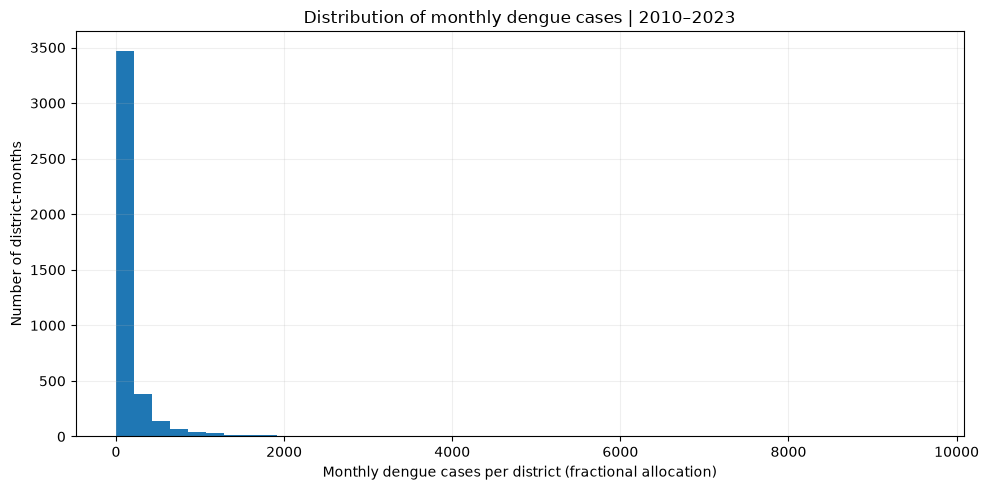

Saved figure: results\figures\notebook10_dengue_distribution.png


In [5]:
summary_statistics = eda[["dengue_cases"]].describe().T
weather_statistics = eda_weather[WEATHER_COLUMNS].describe().T
summary_statistics.to_csv(TABLES_DIR / "notebook10_dengue_descriptive_statistics.csv")
weather_statistics.to_csv(TABLES_DIR / "notebook10_weather_descriptive_statistics.csv")
print("Dengue cases per district-month (2010–2023):")
display(summary_statistics)
print("Weather variables, complete weather months only (2010–2023):")
display(weather_statistics)

fig, ax = plt.subplots()
ax.hist(eda["dengue_cases"], bins=45)
ax.set(xlabel="Monthly dengue cases per district (fractional allocation)", ylabel="Number of district-months", title="Distribution of monthly dengue cases | 2010–2023")
save_figure("notebook10_dengue_distribution.png")

## 6 — Annual dengue trends (2010–2023)
Sum monthly district counts to estimate annual nationwide totals. These are **source-derived case counts**, not incidence rates and not a population-adjusted comparison.

,year,national_dengue_cases
0,2010,25006.000000
1,2011,21751.857143
2,2012,23657.428571
3,2013,22514.000000
4,2014,35644.571429
5,2015,22337.571429
6,2016,34661.857143
7,2017,175074.857143
8,2018,51328.285714
9,2019,96008.428571


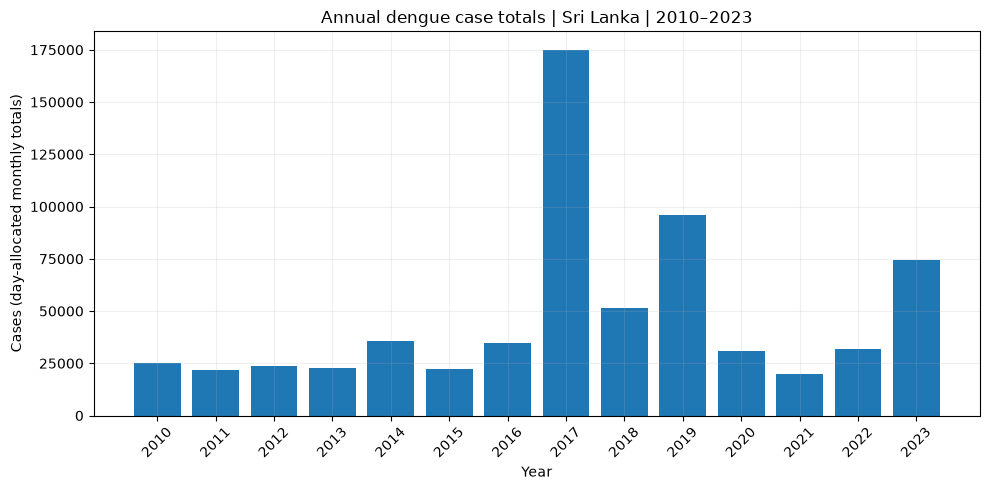

Saved figure: results\figures\notebook10_annual_dengue_2010_2023.png


In [6]:
annual_dengue = eda.groupby("year", as_index=False)["dengue_cases"].sum()
annual_dengue = annual_dengue.rename(columns={"dengue_cases": "national_dengue_cases"})
display(annual_dengue)
annual_dengue.to_csv(TABLES_DIR / "notebook10_annual_dengue_2010_2023.csv", index=False)

fig, ax = plt.subplots()
ax.bar(annual_dengue["year"].astype(str), annual_dengue["national_dengue_cases"])
ax.set(title="Annual dengue case totals | Sri Lanka | 2010–2023", xlabel="Year", ylabel="Cases (day-allocated monthly totals)")
ax.tick_params(axis="x", rotation=45)
save_figure("notebook10_annual_dengue_2010_2023.png")

## 7 — Monthly dengue timeline
Plot monthly totals across all districts to observe outbreak peaks and changes over time. The graph is descriptive; no future months are used as model inputs.

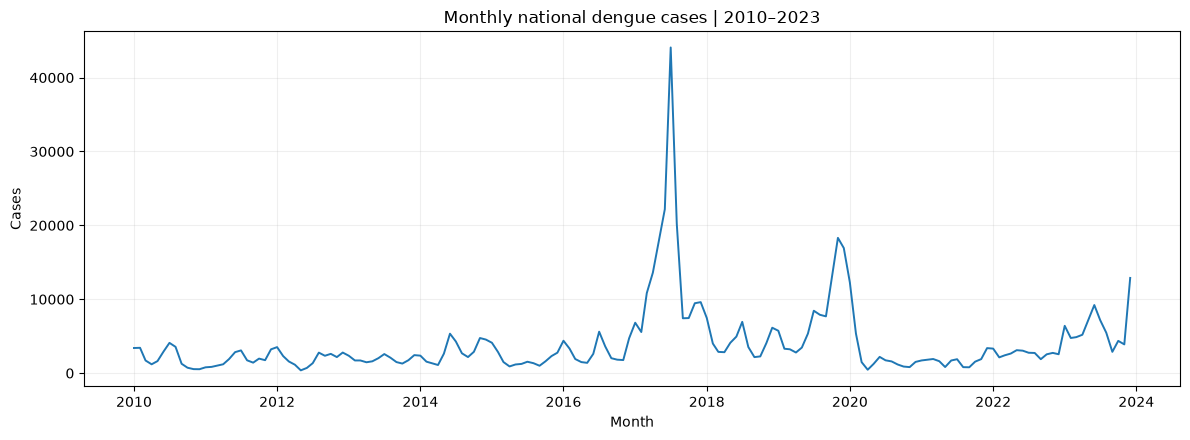

Saved figure: results\figures\notebook10_monthly_dengue_timeline.png
Ten highest-case months (descriptive, not automatically errors):


,date,national_dengue_cases
90,2017-07-01,44077.571429
89,2017-06-01,22183.857143
91,2017-08-01,20208.000000
118,2019-11-01,18306.285714
88,2017-05-01,17847.428571
119,2019-12-01,16931.571429
87,2017-04-01,13599.714286
117,2019-10-01,12885.857143
167,2023-12-01,12885.000000
120,2020-01-01,12268.142857


In [7]:
monthly_national = eda.groupby("date", as_index=False)["dengue_cases"].sum()
monthly_national = monthly_national.rename(columns={"dengue_cases": "national_dengue_cases"})
monthly_national.to_csv(TABLES_DIR / "notebook10_monthly_national_dengue_2010_2023.csv", index=False)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly_national["date"], monthly_national["national_dengue_cases"], linewidth=1.4)
ax.set(title="Monthly national dengue cases | 2010–2023", xlabel="Month", ylabel="Cases")
save_figure("notebook10_monthly_dengue_timeline.png")

print("Ten highest-case months (descriptive, not automatically errors):")
display(monthly_national.nlargest(10, "national_dengue_cases"))

## 8 — Dengue seasonality by calendar month
Calculate the average national dengue cases in each calendar month across **2010–2023**. This describes recurring patterns but cannot prove a causal seasonal mechanism.

,month_number,mean_national_cases,median_national_cases,month_name
0,1,4617.081633,3814.285714,Jan
1,2,3067.653061,3079.928571,Feb
2,3,2740.591837,1811.500000,Mar
3,4,2688.591837,1481.285714,Apr
4,5,3459.714286,1764.000000,May
5,6,4737.357143,2884.357143,Jun
6,7,6823.683673,3584.928571,Jul
7,8,4287.846939,2751.571429,Aug
8,9,2551.479592,1954.000000,Sep
9,10,3203.642857,2114.285714,Oct


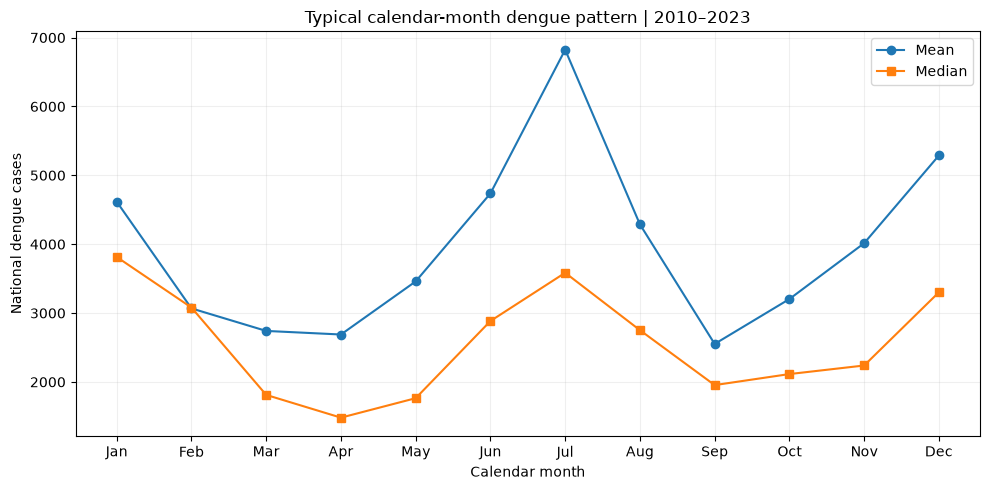

Saved figure: results\figures\notebook10_dengue_seasonality.png


In [8]:
monthly_national["month_number"] = monthly_national["date"].dt.month
seasonality = (monthly_national.groupby("month_number", as_index=False)
               .agg(mean_national_cases=("national_dengue_cases", "mean"),
                    median_national_cases=("national_dengue_cases", "median")))
seasonality["month_name"] = seasonality["month_number"].map(dict(enumerate(MONTH_NAMES, start=1)))
seasonality.to_csv(TABLES_DIR / "notebook10_dengue_seasonality.csv", index=False)
display(seasonality)

fig, ax = plt.subplots()
ax.plot(seasonality["month_number"], seasonality["mean_national_cases"], marker="o", label="Mean")
ax.plot(seasonality["month_number"], seasonality["median_national_cases"], marker="s", label="Median")
ax.set(xticks=range(1, 13), xticklabels=MONTH_NAMES, xlabel="Calendar month", ylabel="National dengue cases", title="Typical calendar-month dengue pattern | 2010–2023")
ax.legend()
save_figure("notebook10_dengue_seasonality.png")

## 9 — District dengue burden
Compare total reported cases across 25 administrative districts for the **same observation period**. Higher totals do not automatically imply higher *risk*, because district populations differ.

,administrative_district,total_cases
0,Colombo,144093.428571
1,Gampaha,84640.714286
2,Kandy,53995.714286
3,Kalutara,41746.000000
4,Jaffna,37573.000000
5,Kurunegala,34700.285714
6,Ratnapura,30100.714286
7,Batticaloa,29006.571429
8,Kegalle,27474.000000
9,Galle,25994.571429


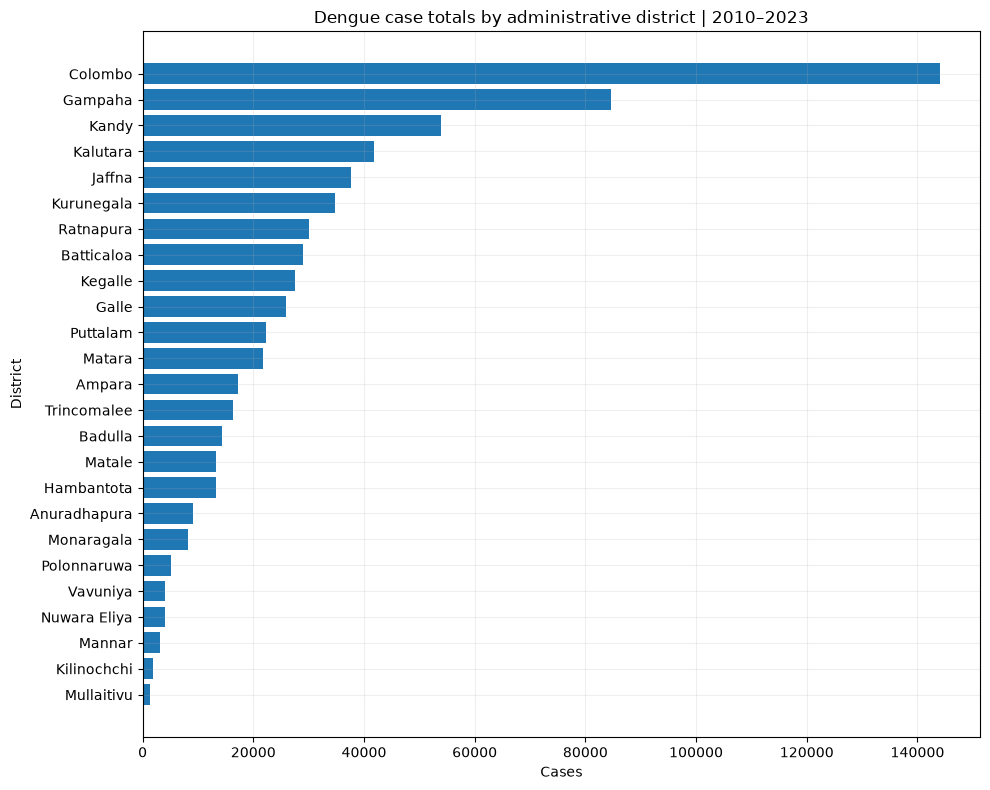

Saved figure: results\figures\notebook10_district_case_totals.png


In [9]:
district_totals = (eda.groupby("administrative_district", as_index=False)["dengue_cases"].sum()
                   .rename(columns={"dengue_cases": "total_cases"})
                   .sort_values("total_cases", ascending=False).reset_index(drop=True))
district_totals.to_csv(TABLES_DIR / "notebook10_district_case_totals_2010_2023.csv", index=False)
display(district_totals)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(district_totals["administrative_district"][::-1], district_totals["total_cases"][::-1])
ax.set(title="Dengue case totals by administrative district | 2010–2023", xlabel="Cases", ylabel="District")
save_figure("notebook10_district_case_totals.png")

## 10 — Weather distributions and seasonal patterns
Weather plots use **complete-weather months only**, avoiding the January 2010 boundary month. Rainfall totals are monthly totals; temperature, humidity and wind speed are monthly means.

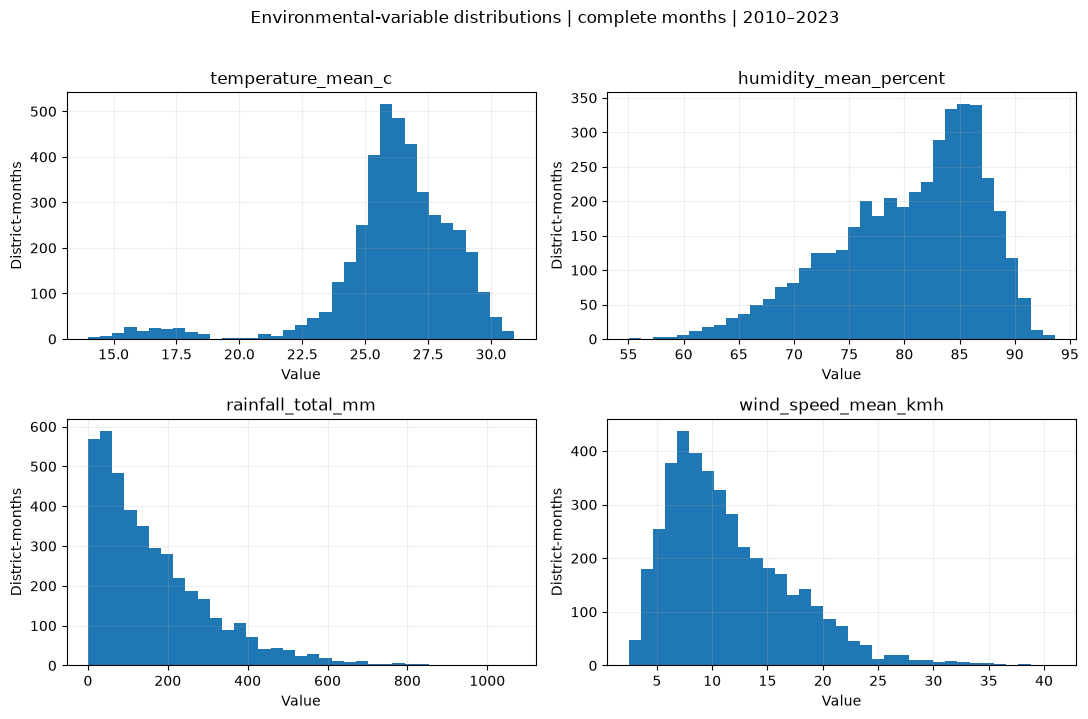

Saved figure: results\figures\notebook10_weather_distributions.png


,month_number,temperature_mean_c,humidity_mean_percent,rainfall_total_mm,wind_speed_mean_kmh
0,1,24.594828,79.716112,131.698747,10.571668
1,2,25.313788,78.206132,84.322592,9.977820
2,3,26.509062,77.383392,79.745184,8.363137
3,4,27.088680,80.359224,141.116878,7.578416
4,5,27.188226,81.375921,184.170735,12.971899
5,6,27.189392,78.323469,113.575184,16.416525
6,7,27.000223,77.147596,109.596020,15.638939
7,8,26.736468,77.847330,127.053735,14.989358
8,9,26.465793,79.412820,154.397898,13.951035
9,10,25.816866,83.514004,300.241898,9.913817


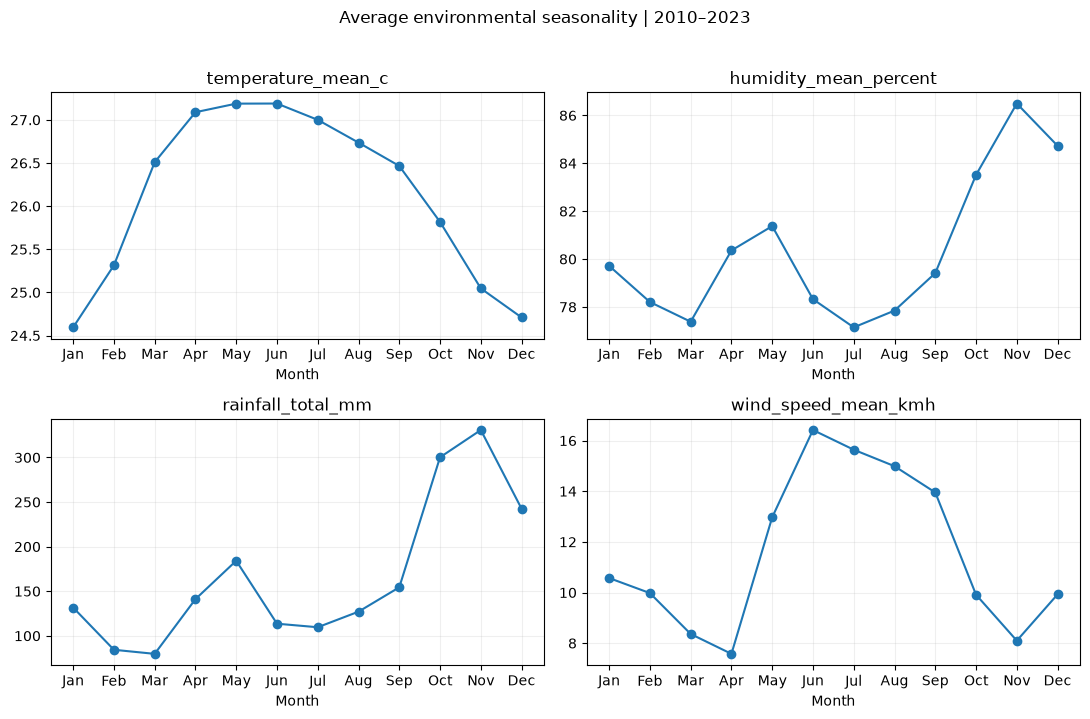

Saved figure: results\figures\notebook10_weather_seasonality.png


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, variable in zip(axes.flat, WEATHER_COLUMNS):
    ax.hist(eda_weather[variable], bins=35)
    ax.set(title=variable, xlabel="Value", ylabel="District-months")
fig.suptitle("Environmental-variable distributions | complete months | 2010–2023", y=1.02)
save_figure("notebook10_weather_distributions.png")

weather_seasonality = eda_weather.groupby("month_number", as_index=False)[WEATHER_COLUMNS].mean()
weather_seasonality.to_csv(TABLES_DIR / "notebook10_weather_seasonality.csv", index=False)
display(weather_seasonality)

fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for ax, variable in zip(axes.flat, WEATHER_COLUMNS):
    ax.plot(weather_seasonality["month_number"], weather_seasonality[variable], marker="o")
    ax.set(title=variable, xticks=range(1, 13), xticklabels=MONTH_NAMES, xlabel="Month")
fig.suptitle("Average environmental seasonality | 2010–2023", y=1.02)
save_figure("notebook10_weather_seasonality.png")

## 11 — Same-month weather–dengue correlations
Compute **Pearson** and **Spearman** correlations across district-month rows. Pearson captures linear association; Spearman captures monotonic rank association. These are pooled descriptive statistics and can be confounded by geography, seasonality, and year. **Do not treat correlation as causation or use 2024 to select features.**

Pearson correlations:


,dengue_cases,temperature_mean_c,humidity_mean_percent,rainfall_total_mm,wind_speed_mean_kmh
dengue_cases,1.000,0.005,0.139,0.105,-0.069
temperature_mean_c,0.005,1.000,-0.526,-0.303,0.390
humidity_mean_percent,0.139,-0.526,1.000,0.699,-0.348
rainfall_total_mm,0.105,-0.303,0.699,1.000,-0.363
wind_speed_mean_kmh,-0.069,0.390,-0.348,-0.363,1.000


Spearman correlations:


,dengue_cases,temperature_mean_c,humidity_mean_percent,rainfall_total_mm,wind_speed_mean_kmh
dengue_cases,1.000,-0.192,0.275,0.213,-0.202
temperature_mean_c,-0.192,1.000,-0.612,-0.476,0.451
humidity_mean_percent,0.275,-0.612,1.000,0.831,-0.355
rainfall_total_mm,0.213,-0.476,0.831,1.000,-0.391
wind_speed_mean_kmh,-0.202,0.451,-0.355,-0.391,1.000


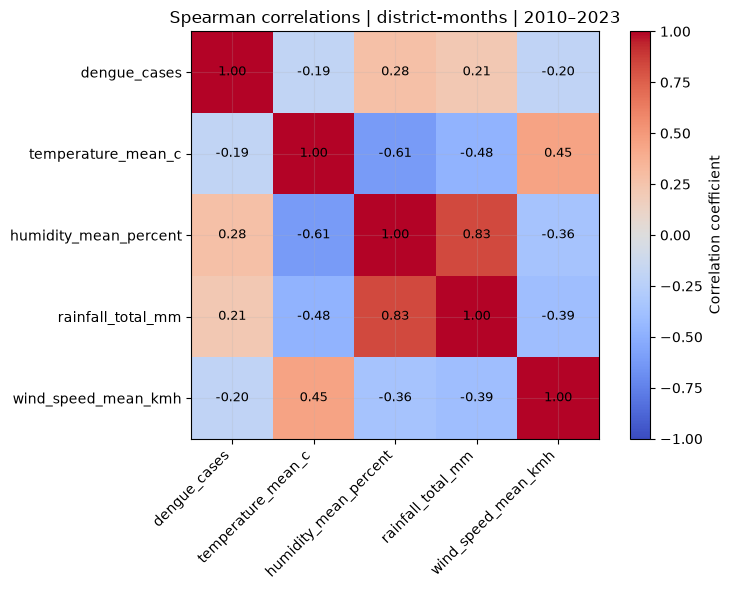

Saved figure: results\figures\notebook10_spearman_correlation_heatmap.png


In [11]:
correlation_columns = ["dengue_cases"] + WEATHER_COLUMNS
pearson = eda_weather[correlation_columns].corr(method="pearson")
spearman = eda_weather[correlation_columns].corr(method="spearman")
pearson.to_csv(TABLES_DIR / "notebook10_pearson_correlations.csv")
spearman.to_csv(TABLES_DIR / "notebook10_spearman_correlations.csv")
print("Pearson correlations:")
display(pearson.round(3))
print("Spearman correlations:")
display(spearman.round(3))

fig, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(spearman.to_numpy(), vmin=-1, vmax=1, cmap="coolwarm")
ax.set(xticks=range(len(correlation_columns)), yticks=range(len(correlation_columns)),
       xticklabels=correlation_columns, yticklabels=correlation_columns,
       title="Spearman correlations | district-months | 2010–2023")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for i in range(len(correlation_columns)):
    for j in range(len(correlation_columns)):
        ax.text(j, i, f"{spearman.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(image, ax=ax, label="Correlation coefficient")
save_figure("notebook10_spearman_correlation_heatmap.png")

## 12 — Exploratory weather lags (not forecasting features)
A *lag-1* weather value is the previous month's weather; *lag-2* is two months earlier, etc. Compute correlations between dengue cases in month **t** and weather from **t−1, t−2, t−3**. These exploratory correlations are not causal effects and are not final feature-selection evidence. **Notebook 11** will build the actual lagged model features, with strict date ordering and a later time-based split.

,weather_variable,lag_months,paired_observations,spearman_correlation
0,temperature_mean_c,0,4175,-0.192387
1,temperature_mean_c,1,4150,-0.205250
2,temperature_mean_c,2,4125,-0.177287
3,temperature_mean_c,3,4100,-0.124266
4,humidity_mean_percent,0,4175,0.275498
5,humidity_mean_percent,1,4150,0.348692
6,humidity_mean_percent,2,4125,0.357380
7,humidity_mean_percent,3,4100,0.274256
8,rainfall_total_mm,0,4175,0.213477
9,rainfall_total_mm,1,4150,0.302927


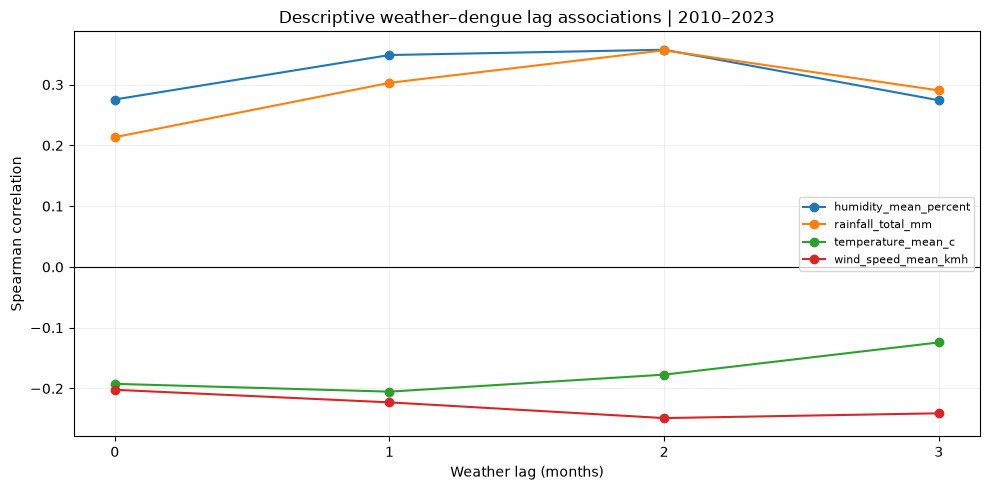

Saved figure: results\figures\notebook10_weather_lag_correlations.png


In [12]:
lag_data = eda_weather.sort_values(["administrative_district", "date"]).copy()
for variable in WEATHER_COLUMNS:
    for lag in (1, 2, 3):
        lag_data[f"{variable}_lag{lag}"] = lag_data.groupby("administrative_district")[variable].shift(lag)

lag_rows = []
for variable in WEATHER_COLUMNS:
    for lag in (0, 1, 2, 3):
        predictor = variable if lag == 0 else f"{variable}_lag{lag}"
        paired = lag_data[["dengue_cases", predictor]].dropna()
        lag_rows.append({
            "weather_variable": variable,
            "lag_months": lag,
            "paired_observations": len(paired),
            "spearman_correlation": paired["dengue_cases"].corr(paired[predictor], method="spearman"),
        })
lag_correlations = pd.DataFrame(lag_rows)
lag_correlations.to_csv(TABLES_DIR / "notebook10_exploratory_lag_correlations.csv", index=False)
display(lag_correlations)

fig, ax = plt.subplots()
for variable, group in lag_correlations.groupby("weather_variable"):
    ax.plot(group["lag_months"], group["spearman_correlation"], marker="o", label=variable)
ax.axhline(0, linewidth=0.8, color="black")
ax.set(title="Descriptive weather–dengue lag associations | 2010–2023", xlabel="Weather lag (months)", ylabel="Spearman correlation", xticks=[0, 1, 2, 3])
ax.legend(fontsize=8)
save_figure("notebook10_weather_lag_correlations.png")

## 13 — Population-adjusted annual dengue incidence (2014–2023)
For each district and year, calculate:

\[\text{Annual cases per 100,000} = \frac{\text{sum of monthly cases in that year}}{\text{annual district population}} \times 100,000\]

Notebook 06 repeats the **annual population estimate** across months, so first verify that each district-year has exactly one population value. These are **reported-case rates**, not infection risk estimates. Population data for 2010–2013 is unavailable and must not be invented.

,administrative_district,mean_annual_cases_per_100k
8,Jaffna,552.894298
4,Colombo,490.288525
3,Batticaloa,449.769935
23,Trincomalee,362.503658
10,Kandy,332.110763
6,Gampaha,303.777022
9,Kalutara,288.280447
11,Kegalle,265.490469
21,Puttalam,236.845284
15,Matale,225.916088


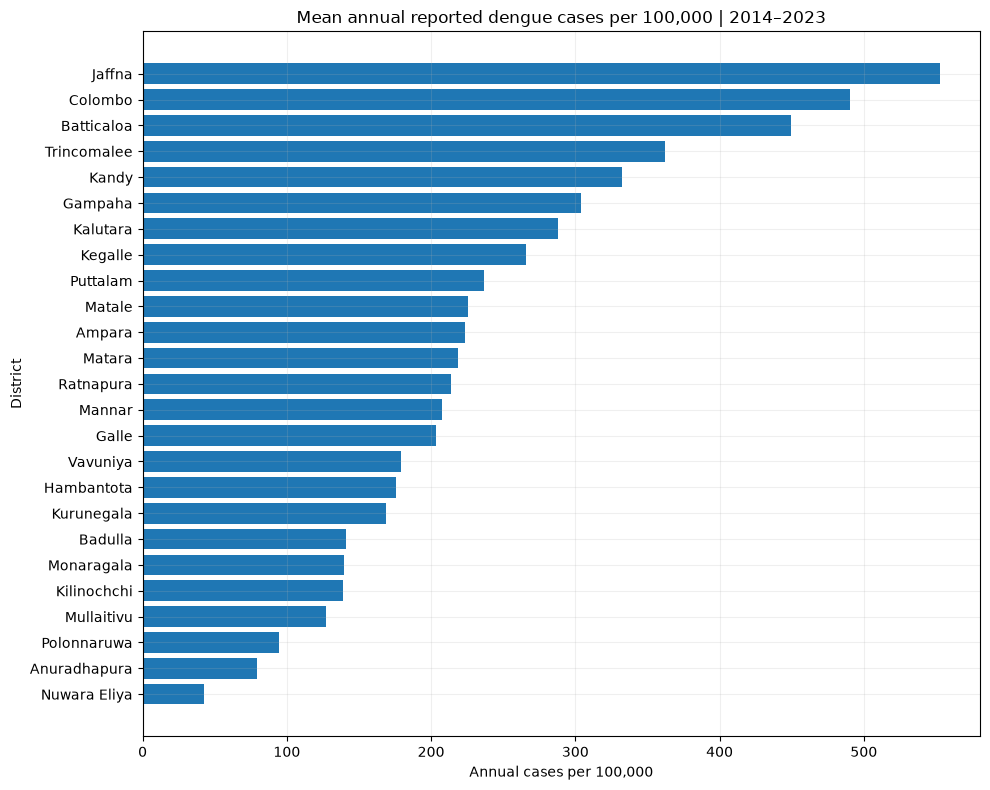

Saved figure: results\figures\notebook10_population_adjusted_district_rates.png


In [13]:
population_consistency = pop_eda.groupby(["administrative_district", "year"])["population"].nunique()
assert population_consistency.eq(1).all(), "Annual population differs across months within district-year"

annual_district_rates = (pop_eda.groupby(["administrative_district", "year"], as_index=False)
                         .agg(annual_cases=("dengue_cases", "sum"),
                              population=("population", "first"),
                              months_observed=("date", "nunique")))
assert annual_district_rates["months_observed"].eq(12).all(), "Expected 12 months per district-year"
annual_district_rates["annual_cases_per_100k"] = (
    annual_district_rates["annual_cases"] / annual_district_rates["population"] * 100_000
)
annual_district_rates.to_csv(TABLES_DIR / "notebook10_annual_district_incidence_2014_2023.csv", index=False)

# Use the same ten-year period for all districts. Mean annual rates describe the average annual burden.
mean_annual_rate = (annual_district_rates.groupby("administrative_district", as_index=False)
                    .agg(mean_annual_cases_per_100k=("annual_cases_per_100k", "mean"))
                    .sort_values("mean_annual_cases_per_100k", ascending=False))
mean_annual_rate.to_csv(TABLES_DIR / "notebook10_mean_annual_incidence_by_district.csv", index=False)
display(mean_annual_rate)

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(mean_annual_rate["administrative_district"][::-1], mean_annual_rate["mean_annual_cases_per_100k"][::-1])
ax.set(title="Mean annual reported dengue cases per 100,000 | 2014–2023", xlabel="Annual cases per 100,000", ylabel="District")
save_figure("notebook10_population_adjusted_district_rates.png")

## 14 — Final audit: saved outputs and test-year protection
Check that the 2024 test year never entered the analytical tables. This notebook **does not** write a transformed model-ready dataset; Notebook 11 handles temporal feature engineering.

In [14]:
assert eda["date"].dt.year.max() == 2023
assert eda_weather["date"].dt.year.max() == 2023
assert pop_eda["date"].dt.year.max() == 2023
assert annual_dengue["year"].max() == 2023
assert annual_district_rates["year"].max() == 2023

saved_tables = sorted(TABLES_DIR.glob("notebook10_*.csv"))
saved_figures = sorted(FIGURES_DIR.glob("notebook10_*.png"))
print(f"Saved {len(saved_tables)} tables and {len(saved_figures)} figures.")
for p in saved_tables + saved_figures:
    print(" -", p.relative_to(PROJECT_ROOT))
assert len(saved_tables) >= 10
assert len(saved_figures) >= 8
print("PASS: Notebook 10 outputs created; 2024 protected from EDA-driven analysis.")

Saved 12 tables and 10 figures.
 - results\tables\notebook10_annual_dengue_2010_2023.csv
 - results\tables\notebook10_annual_district_incidence_2014_2023.csv
 - results\tables\notebook10_dengue_descriptive_statistics.csv
 - results\tables\notebook10_dengue_seasonality.csv
 - results\tables\notebook10_district_case_totals_2010_2023.csv
 - results\tables\notebook10_exploratory_lag_correlations.csv
 - results\tables\notebook10_mean_annual_incidence_by_district.csv
 - results\tables\notebook10_monthly_national_dengue_2010_2023.csv
 - results\tables\notebook10_pearson_correlations.csv
 - results\tables\notebook10_spearman_correlations.csv
 - results\tables\notebook10_weather_descriptive_statistics.csv
 - results\tables\notebook10_weather_seasonality.csv
 - results\figures\notebook10_annual_dengue_2010_2023.png
 - results\figures\notebook10_dengue_distribution.png
 - results\figures\notebook10_dengue_seasonality.png
 - results\figures\notebook10_district_case_totals.png
 - results\figures\no

## 15 — Research interpretation template (complete after running)

Record the **observed numerical results** from the executed tables rather than assuming patterns in advance:

- **Annual trend:** Which years had the highest/lowest nationwide dengue totals in `annual_dengue`?
- **Seasonality:** Which calendar months had higher mean/median totals in `seasonality`?
- **District burden:** Which districts had the highest total case counts in `district_totals`?
- **Population-adjusted burden:** Which districts had higher *annual cases per 100,000* in `mean_annual_rate`? Do those rankings differ from absolute counts?
- **Environmental association:** What do the Pearson, Spearman and lag tables actually show? Note whether coefficients are weak, moderate or strong without claiming causation.
- **Data limitations:** Weekly-to-monthly allocation assumes uniform daily incidence within a reporting week; weather weekly-to-monthly conversion is approximate; the 2010/2024 boundary months are incomplete; population data begins in 2014; monthly case totals can be fractional.

**Next:** Notebook 11 — Temporal Feature Engineering. It should use the selected modeling dataset, construct past-only lags and rolling statistics, and create a *next-month* dengue target. Notebook 12 then performs the chronological split, keeping 2024 untouched.